# Risk Stratification and Decision Threshold Selection

## Objective

The readmission model produces a calibrated probability representing the
estimated likelihood of 30-day hospital readmission.

This notebook converts those probabilities into operational risk categories.

The goals are to:

1. Evaluate classification performance across different probability thresholds.
2. Study the trade-off between recall and precision.
3. Select an operational threshold for identifying high-risk patients.
4. Define Low, Moderate, and High risk groups.
5. Evaluate the final risk-stratification system on the untouched test set.

The test set will not be used to choose thresholds.

In [1]:
# Loading necessary libraries for risk stratification analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

from xgboost import XGBClassifier

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load the processed clinical feature dataset, the same source used by
# Notebook 05 (probability calibration)

DATA_PATH = Path("../data/processed/clinical_features.csv")
TARGET = "readmitted_30_days"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nReadmission distribution:")
print(df[TARGET].value_counts())

Dataset shape: (101766, 29)

Readmission distribution:
readmitted_30_days
False    90409
True     11357
Name: count, dtype: int64


In [3]:
# Exclude death-related discharges from the modeling population, exactly as
# in Notebook 05. Deceased patients cannot be readmitted.

print("Encounters before filtering:", len(df))

death_mask = (
    df["discharge_disposition"]
    .astype(str)
    .str.contains("Expired", case=False, na=False)
)

print("Death-related encounters:", death_mask.sum())

df = df.loc[~death_mask].copy()

print("Encounters after filtering:", len(df))
print(
    "30-day readmission rate:",
    round(df[TARGET].astype(int).mean(), 4)
)

Encounters before filtering: 101766
Death-related encounters: 1652
Encounters after filtering: 100114
30-day readmission rate: 0.1134


In [4]:
# Defining model features and preparing the feature matrix, target vector, and patient groups

# Same 23 model features as Notebook 05
model_features = [
    "age_midpoint",
    "gender",
    "race",
    "admission_type",
    "admission_source",
    "discharge_disposition",
    "length_of_stay",
    "previous_inpatient_visits",
    "previous_outpatient_visits",
    "previous_emergency_visits",
    "diagnosis_count",
    "lab_procedure_count",
    "procedure_count",
    "medication_count",
    "hba1c_result",
    "glucose_result",
    "insulin_status",
    "diabetes_medication",
    "primary_diagnosis_category",
    "secondary_diagnosis_category",
    "tertiary_diagnosis_category",
    "total_previous_visits",
    "has_previous_inpatient_visit",
]

X = df[model_features].copy()
y = df[TARGET].astype(int)
groups = df["patient_id"]

assert X.shape[1] == len(model_features), "Unexpected number of model features"
assert len(X) == len(y) == len(groups), "Model inputs have different row counts"
assert not df["discharge_disposition"].astype(str).str.contains(
    "Expired", case=False, na=False
).any(), "Death-related encounters remain in the modeling dataset"

print("Features:", X.shape[1])
print("Encounters:", len(X))
print("Target positive rate:", round(y.mean(), 4))
print("Unique patients:", groups.nunique())

Features: 23
Encounters: 100114
Target positive rate: 0.1134
Unique patients: 70439


## 5. Patient-Level Train / Calibration / Test Split

Patients may have multiple hospital encounters.

Therefore, splitting individual rows could place encounters belonging to the
same patient into multiple datasets and cause data leakage.

We use `GroupShuffleSplit` with `patient_id` as the grouping variable and the
same random seed and split sequence as Notebook 05, so both notebooks use
identical train, calibration, and test partitions.

The datasets are approximately:

- 64% model training
- 16% calibration / threshold development
- 20% final testing

The final test set remains untouched during threshold selection.

In [5]:
# First split: 80% development, 20% test

split_test = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

dev_idx, test_idx = next(
    split_test.split(X, y, groups=groups)
)

X_dev = X.iloc[dev_idx].copy()
y_dev = y.iloc[dev_idx].copy()
groups_dev = groups.iloc[dev_idx].copy()

X_test = X.iloc[test_idx].copy()
y_test = y.iloc[test_idx].copy()
test_groups = groups.iloc[test_idx].copy()


# Second split:
# 80% of development -> model training
# 20% of development -> calibration / threshold development

split_cal = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, cal_idx = next(
    split_cal.split(
        X_dev,
        y_dev,
        groups=groups_dev
    )
)

X_model_train = X_dev.iloc[train_idx].copy()
y_model_train = y_dev.iloc[train_idx].copy()
model_train_groups = groups_dev.iloc[train_idx].copy()

X_cal = X_dev.iloc[cal_idx].copy()
y_cal = y_dev.iloc[cal_idx].copy()
cal_groups = groups_dev.iloc[cal_idx].copy()

In [6]:
print("MODEL TRAINING SET")
print("------------------")
print("Encounters:", len(X_model_train))
print("Patients:", model_train_groups.nunique())
print("Positive rate:", round(y_model_train.mean(), 4))

print("\nCALIBRATION SET")
print("------------------")
print("Encounters:", len(X_cal))
print("Patients:", cal_groups.nunique())
print("Positive rate:", round(y_cal.mean(), 4))

print("\nTEST SET")
print("------------------")
print("Encounters:", len(X_test))
print("Patients:", test_groups.nunique())
print("Positive rate:", round(y_test.mean(), 4))

MODEL TRAINING SET
------------------
Encounters: 63949
Patients: 45080
Positive rate: 0.1128

CALIBRATION SET
------------------
Encounters: 16090
Patients: 11271
Positive rate: 0.1142

TEST SET
------------------
Encounters: 20075
Patients: 14088
Positive rate: 0.1148


In [7]:
# Checking for patient-level leakage between the model training, calibration, and test sets

train_patients = set(model_train_groups.unique())
cal_patients = set(cal_groups.unique())
test_patients = set(test_groups.unique())

train_cal_overlap = train_patients.intersection(cal_patients)
train_test_overlap = train_patients.intersection(test_patients)
cal_test_overlap = cal_patients.intersection(test_patients)

print("PATIENT-LEVEL LEAKAGE CHECK")
print("---------------------------")

print(
    "Model train ↔ Calibration:",
    len(train_cal_overlap)
)

print(
    "Model train ↔ Test:",
    len(train_test_overlap)
)

print(
    "Calibration ↔ Test:",
    len(cal_test_overlap)
)

assert len(train_cal_overlap) == 0
assert len(train_test_overlap) == 0
assert len(cal_test_overlap) == 0

print("\n✓ All three datasets are patient-independent.")

PATIENT-LEVEL LEAKAGE CHECK
---------------------------
Model train ↔ Calibration: 0
Model train ↔ Test: 0
Calibration ↔ Test: 0

✓ All three datasets are patient-independent.


## 7. Rebuild the Final XGBoost Pipeline

We recreate the selected shallow XGBoost model from the previous modeling
experiments.

The model is trained only on the model-training partition.

Categorical variables are imputed and one-hot encoded, while numerical
variables are median-imputed.

In [8]:
# Identifying categorical and numerical features in the model training set

categorical_features = X_model_train.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numerical_features = X_model_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Total:", len(categorical_features) + len(numerical_features))

Categorical features: 12
Numerical features: 11
Total: 23


In [9]:
# Creating preprocessing pipelines for numerical and categorical features

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("✓ Preprocessor created.")

✓ Preprocessor created.


In [10]:
# Calculating the scale_pos_weight for handling class imbalance in the model training set

negative_count = (y_model_train == 0).sum()
positive_count = (y_model_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative cases:", negative_count)
print("Positive cases:", positive_count)
print(
    "scale_pos_weight:",
    round(scale_pos_weight, 4)
)

Negative cases: 56734
Positive cases: 7215
scale_pos_weight: 7.8633


In [11]:
# Training an XGBoost classifier with the preprocessor and handling class imbalance

xgb_classifier = XGBClassifier(
    n_estimators=400,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

base_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_classifier)
    ]
)

print("Training XGBoost...")

base_model.fit(
    X_model_train,
    y_model_train
)

print("✓ XGBoost trained successfully.")

Training XGBoost...


✓ XGBoost trained successfully.


In [12]:
# Evaluating the raw predicted probabilities on the calibration set

cal_raw_prob = base_model.predict_proba(X_cal)[:, 1]

print("Raw mean probability:", round(cal_raw_prob.mean(), 4))
print("Actual calibration rate:", round(y_cal.mean(), 4))

Raw mean probability: 0.4595
Actual calibration rate: 0.1142


In [13]:
# rebuilding the calibration model using Platt scaling

platt_calibrator = LogisticRegression(
    random_state=42
)

platt_calibrator.fit(
    cal_raw_prob.reshape(-1, 1),
    y_cal
)

calibrated_prob = platt_calibrator.predict_proba(
    cal_raw_prob.reshape(-1, 1)
)[:, 1]

print("CALIBRATION CHECK")
print("-----------------")
print(
    "Raw mean probability:",
    round(cal_raw_prob.mean(), 4)
)
print(
    "Calibrated mean probability:",
    round(calibrated_prob.mean(), 4)
)
print(
    "Actual readmission rate:",
    round(y_cal.mean(), 4)
)

CALIBRATION CHECK


-----------------
Raw mean probability: 0.4595
Calibrated mean probability: 0.1143
Actual readmission rate: 0.1142


## 10. Operational Threshold Analysis

A calibrated probability must be converted into an operational decision.

Using a default threshold of 0.50 is not appropriate simply because this is a
binary classification problem.

Thirty-day readmission is relatively uncommon, and the operational cost of
missing a genuinely high-risk patient may differ from the cost of reviewing
a patient who ultimately is not readmitted.

Threshold selection is therefore performed using the calibration set only.

The final test set remains untouched.

In [14]:
# Evaluating model performance across different probability thresholds

thresholds = np.arange(
    0.05,
    0.31,
    0.01
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        calibrated_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_cal,
        predictions
    ).ravel()

    precision = precision_score(
        y_cal,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_cal,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_cal,
        predictions,
        zero_division=0
    )

    specificity = tn / (tn + fp)

    flagged = predictions.sum()

    flagged_rate = flagged / len(predictions)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1": f1,
        "Patients Flagged": flagged,
        "Flagged Rate": flagged_rate,
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "True Negatives": tn
    })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df.round(4)

,Threshold,Precision,Recall,Specificity,F1,Patients Flagged,Flagged Rate,True Positives,False Positives,False Negatives,True Negatives
0,0.05,0.1219,0.9652,0.1036,0.2164,14550,0.9043,1773,12777,64,1476
1,0.06,0.1290,0.9238,0.1962,0.2264,13153,0.8175,1697,11456,140,2797
2,0.07,0.1383,0.8699,0.3016,0.2387,11553,0.7180,1598,9955,239,4298
3,0.08,0.1488,0.8122,0.4010,0.2515,10030,0.6234,1492,8538,345,5715
4,0.09,0.1567,0.7496,0.4801,0.2592,8787,0.5461,1377,7410,460,6843
5,0.10,0.1661,0.6941,0.5510,0.2681,7675,0.4770,1275,6400,562,7853
6,0.11,0.1758,0.6396,0.6134,0.2758,6685,0.4155,1175,5510,662,8743
7,0.12,0.1860,0.5830,0.6712,0.2820,5758,0.3579,1071,4687,766,9566
8,0.13,0.1978,0.5275,0.7243,0.2877,4899,0.3045,969,3930,868,10323
9,0.14,0.2067,0.4698,0.7676,0.2871,4175,0.2595,863,3312,974,10941


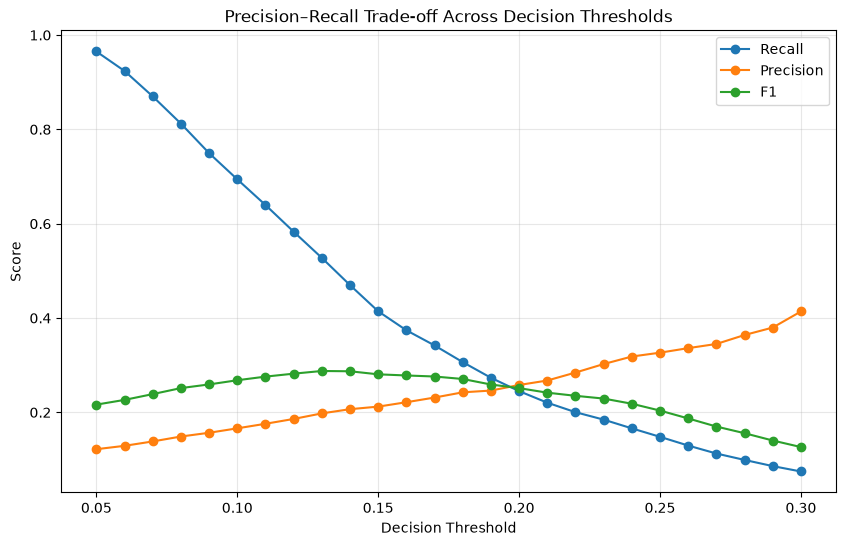

In [15]:
# Plotting Precision, Recall, and F1 Score Across Different Decision Thresholds

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title(
    "Precision–Recall Trade-off Across Decision Thresholds"
)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 12. Operational Threshold Selection

Based on the calibration-set analysis, an operational threshold of 0.15
is selected for the prototype.

At this threshold, the calibration-set recall, specificity, and flagged rate
are shown in the selected-threshold table in the next cell.

This threshold represents a compromise between identifying higher-risk
patients and limiting the number of encounters requiring intervention.

The threshold is not presented as a clinically validated universal cutoff.
In a real deployment, it would need to be selected with hospital-specific
capacity, intervention cost, clinical priorities, and prospective validation.

In [16]:
# Selecting the row corresponding to the chosen decision threshold

SELECTED_THRESHOLD = 0.15

selected_row = threshold_df.loc[
    np.isclose(
        threshold_df["Threshold"],
        SELECTED_THRESHOLD
    )
]

selected_row.round(4)

,Threshold,Precision,Recall,Specificity,F1,Patients Flagged,Flagged Rate,True Positives,False Positives,False Negatives,True Negatives
10,0.15,0.2122,0.4143,0.8017,0.2806,3587,0.2229,761,2826,1076,11427


## 13. Risk Stratification

Calibrated probabilities are converted into operational risk tiers.

For this prototype:

- **Low Risk:** probability < 0.10
- **Moderate Risk:** probability from 0.10 to < 0.15
- **High Risk:** probability >= 0.15

The High-Risk boundary corresponds to the selected operational intervention
threshold.

These categories represent model-based risk strata rather than clinical
diagnoses.

In [17]:
# Assigning Risk Tiers Based on Calibrated Probabilities

def assign_risk_tier(probability):
    if probability < 0.10:
        return "Low"
    elif probability < 0.15:
        return "Moderate"
    else:
        return "High"


cal_risk_tiers = pd.Series(
    calibrated_prob
).apply(assign_risk_tier)

cal_risk_tiers.value_counts()

Low         8415
Moderate    4088
High        3587
Name: count, dtype: int64

In [18]:
# Calculating and Displaying the Distribution of Risk Tiers

risk_distribution = (
    cal_risk_tiers
    .value_counts()
    .rename_axis("Risk Tier")
    .reset_index(name="Encounters")
)

risk_distribution["Percentage"] = (
    risk_distribution["Encounters"]
    / len(cal_risk_tiers)
    * 100
)

risk_distribution

,Risk Tier,Encounters,Percentage
0,Low,8415,52.299565
1,Moderate,4088,25.407085
2,High,3587,22.293350


In [19]:
# Validating Risk Tiers Against Actual Readmissions

risk_validation = pd.DataFrame({
    "Risk Tier": cal_risk_tiers.values,
    "Actual Readmission": y_cal.to_numpy(),
    "Predicted Probability": calibrated_prob
})

tier_summary = (
    risk_validation
    .groupby("Risk Tier")
    .agg(
        Encounters=("Actual Readmission", "size"),
        Readmissions=("Actual Readmission", "sum"),
        Observed_Readmission_Rate=(
            "Actual Readmission",
            "mean"
        ),
        Mean_Predicted_Risk=(
            "Predicted Probability",
            "mean"
        )
    )
)

tier_summary = tier_summary.reindex(
    ["Low", "Moderate", "High"]
)

tier_summary.round(4)

,Encounters,Readmissions,Observed_Readmission_Rate,Mean_Predicted_Risk
Risk Tier,,,,
Low,8415,562,0.0668,0.0676
Moderate,4088,514,0.1257,0.1225
High,3587,761,0.2122,0.2143


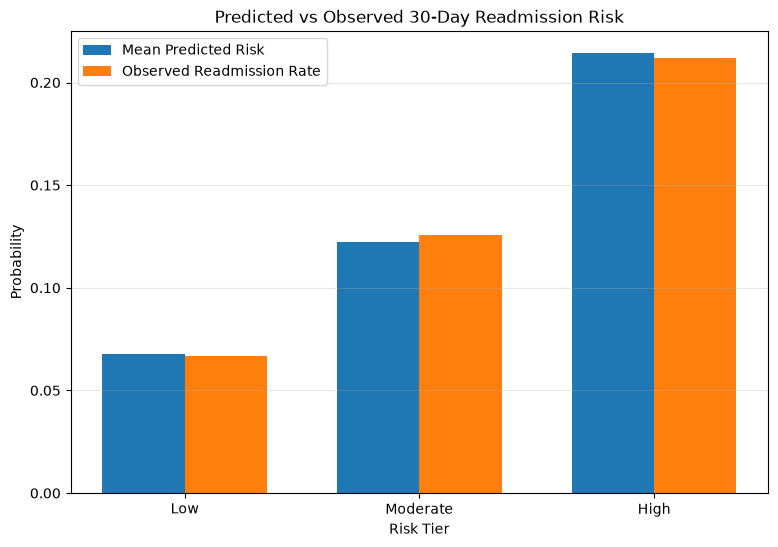

In [20]:
# Plotting Predicted vs Observed Readmission Risk by Risk Tier

plot_data = tier_summary.reset_index()

x = np.arange(len(plot_data))

width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width / 2,
    plot_data["Mean_Predicted_Risk"],
    width,
    label="Mean Predicted Risk"
)

plt.bar(
    x + width / 2,
    plot_data["Observed_Readmission_Rate"],
    width,
    label="Observed Readmission Rate"
)

plt.xticks(
    x,
    plot_data["Risk Tier"]
)

plt.ylabel("Probability")
plt.xlabel("Risk Tier")

plt.title(
    "Predicted vs Observed 30-Day Readmission Risk"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

## 16. Final Evaluation on the Untouched Test Set

The model architecture, probability calibration method, operational threshold,
and risk-tier boundaries have now been fixed using only the training and
calibration datasets.

The untouched patient-level test set is used only for final evaluation.

No model parameters, calibration parameters, thresholds, or risk-tier
boundaries will be modified based on these results.

In [21]:
# Raw XGBoost scores on the untouched test set
test_raw_prob = base_model.predict_proba(X_test)[:, 1]

# Platt calibration operates on the model score,
# not directly on the original patient features.
test_calibrated_prob = platt_calibrator.predict_proba(
    test_raw_prob.reshape(-1, 1)
)[:, 1]

print("Test predictions generated:", len(test_calibrated_prob))
print(
    "Mean calibrated probability:",
    round(test_calibrated_prob.mean(), 4)
)
print(
    "Actual readmission rate:",
    round(y_test.mean(), 4)
)

Test predictions generated: 20075
Mean calibrated probability: 0.1133
Actual readmission rate: 0.1148


In [22]:
# Applying frozen risk tier thresholds to the test set

test_risk_tiers = pd.Series(
    test_calibrated_prob,
    index=y_test.index
).apply(assign_risk_tier)

test_risk_distribution = (
    test_risk_tiers
    .value_counts()
    .rename_axis("Risk Tier")
    .reset_index(name="Encounters")
)

test_risk_distribution["Percentage"] = (
    test_risk_distribution["Encounters"]
    / len(test_risk_tiers)
    * 100
)

test_risk_distribution

,Risk Tier,Encounters,Percentage
0,Low,10630,52.951432
1,Moderate,5115,25.479452
2,High,4330,21.569116


In [ ]:
#Validating the tiers

test_risk_validation = pd.DataFrame({
    "Risk Tier": test_risk_tiers.values,
    "Actual Readmission": y_test.to_numpy(),
    "Predicted Probability": test_calibrated_prob
})

test_tier_summary = (
    test_risk_validation
    .groupby("Risk Tier")
    .agg(
        Encounters=("Actual Readmission", "size"),
        Readmissions=("Actual Readmission", "sum"),
        Observed_Readmission_Rate=(
            "Actual Readmission",
            "mean"
        ),
        Mean_Predicted_Risk=(
            "Predicted Probability",
            "mean"
        )
    )
)

test_tier_summary = test_tier_summary.reindex(
    ["Low", "Moderate", "High"]
)

test_tier_summary.round(4)

,Encounters,Readmissions,Observed_Readmission_Rate,Mean_Predicted_Risk
Risk Tier,,,,
Low,10630,761,0.0716,0.0679
Moderate,5115,605,0.1183,0.1224
High,4330,939,0.2169,0.2138


In [24]:
#Final threshold performance on the test set

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

test_pred = (
    test_calibrated_prob >= SELECTED_THRESHOLD
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred
).ravel()

test_precision = precision_score(
    y_test,
    test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    test_pred
)

test_specificity = tn / (tn + fp)

test_f1 = f1_score(
    y_test,
    test_pred
)

test_accuracy = accuracy_score(
    y_test,
    test_pred
)

print("FINAL OPERATIONAL TEST PERFORMANCE")
print("----------------------------------")
print("Threshold   :", SELECTED_THRESHOLD)
print("Accuracy    :", round(test_accuracy, 4))
print("Precision   :", round(test_precision, 4))
print("Recall      :", round(test_recall, 4))
print("Specificity :", round(test_specificity, 4))
print("F1 Score    :", round(test_f1, 4))

print("\nCONFUSION MATRIX")
print("----------------")
print("True negatives :", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives :", tp)

print(
    "\nPatients flagged:",
    int(test_pred.sum())
)

print(
    "Flagged rate:",
    round(test_pred.mean(), 4)
)

FINAL OPERATIONAL TEST PERFORMANCE
----------------------------------
Threshold   : 0.15
Accuracy    : 0.763
Precision   : 0.2169
Recall      : 0.4074
Specificity : 0.8092
F1 Score    : 0.283

CONFUSION MATRIX
----------------
True negatives : 14379
False positives: 3391
False negatives: 1366
True positives : 939

Patients flagged: 4330
Flagged rate: 0.2157


In [25]:
# Final test set calibration

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

final_metrics = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Brier Score",
        "Log Loss"
    ],
    "Value": [
        roc_auc_score(
            y_test,
            test_calibrated_prob
        ),
        average_precision_score(
            y_test,
            test_calibrated_prob
        ),
        brier_score_loss(
            y_test,
            test_calibrated_prob
        ),
        log_loss(
            y_test,
            test_calibrated_prob
        )
    ]
})

final_metrics.round(4)

,Metric,Value
0,ROC-AUC,0.6655
1,PR-AUC,0.2230
2,Brier Score,0.0971
3,Log Loss,0.3374


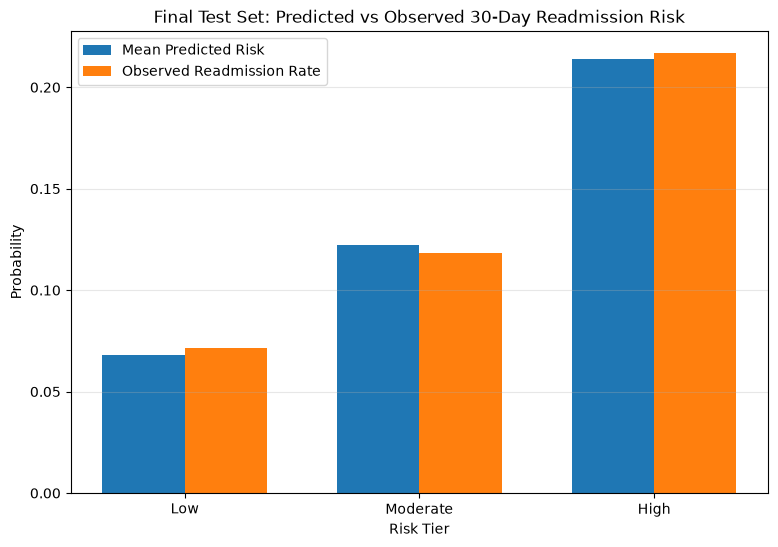

In [26]:
#Final test risk tier plot

plot_data = test_tier_summary.reset_index()

x = np.arange(len(plot_data))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width / 2,
    plot_data["Mean_Predicted_Risk"],
    width,
    label="Mean Predicted Risk"
)

plt.bar(
    x + width / 2,
    plot_data["Observed_Readmission_Rate"],
    width,
    label="Observed Readmission Rate"
)

plt.xticks(
    x,
    plot_data["Risk Tier"]
)

plt.xlabel("Risk Tier")
plt.ylabel("Probability")
plt.title(
    "Final Test Set: Predicted vs Observed "
    "30-Day Readmission Risk"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()